# Baseline model: did a school report any seclusion?

This notebook walks through the team's first model one step at a time. It answers one yes/no
question per school: did the school report at least one seclusion incident? The answer gives
every later model a fair score to beat.

It calls the same functions as `scripts/train_baseline.py`, so the notebook and the script
always give the same numbers. The modeling code lives in `scripts/baseline_features.py` and
`scripts/train_baseline.py`; change it there, not here. Background and design choices are in
`docs/modeling/README_baseline.md`.

**Plan:** train on 2017-18, test once on 2021-22 (a year the models never see), and compare six
models with 5-fold cross-validation grouped by district.

**Data:** run `python scripts/download_data.py` from the repository root first. It puts the
cleaned files in `data/processed/`.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

# Works when the kernel starts in notebooks/ (Jupyter, VS Code) or in the project root.
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().resolve().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import baseline_features as bf
import train_baseline as tb

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_YEARS = ["201718"]
TEST_YEAR = "202122"
CV_FOLDS = 5
SEED = 42
FAST = False  # True = fewer trees, for a quick look; the reported numbers use False

pd.set_option("display.float_format", "{:.3f}".format)
print("data:", DATA_DIR.relative_to(PROJECT_ROOT))

data: data/processed


## 1. Load and filter the data

Each year keeps the rows that pass the modeling filters, in this order:

1. `flag_analysis_ready` is True
2. the seclusion count is present (an unknown outcome is never counted as "no seclusion")
3. enrollment is at least 30 (rates for tiny schools are noise)
4. staffing is plausible (no FTE above enrollment, support staff at most 20 per 100 students,
   teachers at most 50 per 100)

The target is `any_seclusion = 1 if seclusion_instances >= 1 else 0`.

In [2]:
train = tb.prepare_years(TRAIN_YEARS, DATA_DIR, exclude_states=None)
test = tb.prepare_years([TEST_YEAR], DATA_DIR, exclude_states=None)

filters = pd.DataFrame({**train.filter_reports, **test.filter_reports})
filters.index.name = "rows left after"
filters

,201718,202122
rows left after,,
input,91013,93094
analysis_ready,91013,93094
outcome_present,91013,93094
enrollment_ge_30,87783,89839
plausible_staffing,87684,89713


In [3]:
pd.DataFrame(
    {
        "schools": [len(train.frame), len(test.frame)],
        "any seclusion": [int(train.target.sum()), int(test.target.sum())],
        "positive rate": [train.target.mean(), test.target.mean()],
        "districts": [train.frame["leaid"].nunique(), test.frame["leaid"].nunique()],
    },
    index=["train " + "+".join(TRAIN_YEARS), "test " + TEST_YEAR],
)

,schools,any seclusion,positive rate,districts
train 201718,87684,5874,0.067,16811
test 202122,89713,6470,0.072,16774


About 7% of schools report any seclusion, so the classes are imbalanced. That is why the main
metric is PR-AUC (precision-recall), not accuracy: a model that always says "no" would be 93%
accurate and useless.

## 2. Features

`FeatureBuilder` turns the cleaned columns into model inputs. Anything it learns (the caps on
psychologists and social workers per 100 students, the list of states) comes from training rows
only. Seclusion columns, quality flags, IDs and names are never features.

In [4]:
builder = bf.FeatureBuilder(include_state=False).fit(train.frame)
print(len(builder.feature_names), "features without state:")
print(", ".join(builder.feature_names))

with_state = bf.FeatureBuilder(include_state=True).fit(train.frame)
print()
print(len(with_state.feature_names), "features with state (one column per training state)")

21 features without state:
log_enrollment, gb_elementary, gb_middle, gb_high, gb_span, gb_other, gb_na, is_sped, is_alt, is_charter, is_jj, is_magnet, pct_idea, pct_504, pct_el, pct_idea_na, pct_504_na, pct_el_na, psych_p100, social_p100, log_lea_enrollment

72 features with state (one column per training state)


In [5]:
builder.transform(train.frame).describe().T

,count,mean,std,min,25%,50%,75%,max
log_enrollment,87684.000,6.021,0.796,3.434,5.642,6.118,6.509,9.567
gb_elementary,87684.000,0.391,0.488,0.000,0.000,0.000,1.000,1.000
gb_middle,87684.000,0.139,0.346,0.000,0.000,0.000,0.000,1.000
gb_high,87684.000,0.176,0.381,0.000,0.000,0.000,0.000,1.000
gb_span,87684.000,0.293,0.455,0.000,0.000,0.000,1.000,1.000
gb_other,87684.000,0.002,0.041,0.000,0.000,0.000,0.000,1.000
gb_na,87684.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
is_sped,87684.000,0.016,0.125,0.000,0.000,0.000,0.000,1.000
is_alt,87684.000,0.025,0.155,0.000,0.000,0.000,0.000,1.000
is_charter,87684.000,0.075,0.263,0.000,0.000,0.000,0.000,1.000


## 3. The six models

All have fixed settings (no tuning this round) and no class weights, so their probabilities
stay usable. M2 and M5 add state; comparing them with M1 and M4 shows how much state adds.

In [6]:
specs = tb.build_models(SEED, FAST)
pd.DataFrame(
    [(s.model_id, s.description, s.include_state) for s in specs],
    columns=["model", "description", "uses state"],
).set_index("model")

,description,uses state
model,,
M0,No-skill baseline (predicts the training posit...,False
M1,"Logistic regression, no state",False
M2,"Logistic regression, with state",True
M3,"Random forest, no state",False
M4,"Gradient boosting, no state",False
M5,"Gradient boosting, with state",True


## 4. Cross-validation on 2017-18

5-fold `GroupKFold` by district (`leaid`): a district is never in both the fitting rows and the
scoring rows, because schools in one district share policy and reporting habits. The folds are
computed once and reused for every model, and the features are refit inside every fold.

This is the slowest step (a few minutes).

In [7]:
folds = tb.group_folds(train.frame["leaid"], CV_FOLDS)
cv = tb.cross_validate(specs, train, folds)

cv_view = cv.groupby("model")[["pr_auc", "pr_auc_lift", "roc_auc", "recall_at_top10"]].agg(["mean", "std"])
cv_view

pr_auc       pr_auc_lift       roc_auc       recall_at_top10      
        mean   std        mean   std    mean   std            mean   std
model                                                                   
M0     0.067 0.006       1.000 0.000   0.500 0.000           0.100 0.000
M1     0.117 0.008       1.748 0.138   0.662 0.018           0.181 0.019
M2     0.325 0.049       4.885 0.874   0.833 0.016           0.470 0.056
M3     0.147 0.013       2.196 0.141   0.714 0.016           0.250 0.013
M4     0.130 0.010       1.947 0.148   0.704 0.022           0.223 0.018
M5     0.338 0.049       5.073 0.841   0.839 0.007           0.469 0.045

## 5. Test once on 2021-22

Every model is refit on all 2017-18 rows and scores 2021-22 once. Schools whose `combokey` is
not in 2017-18 are "new schools", the closest thing to brand-new data.

Caution: `pct_504` and `pct_el` are almost never missing in 2017-18 but often missing in
2021-22 (a reporting change). The last table scores the two groups separately.

In [8]:
new_mask = ~test.frame["combokey"].isin(set(train.frame["combokey"])).to_numpy()
missing_mask = test.frame[["pct_504", "pct_el"]].isna().any(axis=1).to_numpy()
y_test = test.target.to_numpy()

scores, fitted = {}, {}
test_rows, new_rows, missing_rows = [], [], []
for spec in specs:
    fitted_builder, model, score = tb.fit_predict(spec, train.frame, train.target, test.frame)
    scores[spec.model_id], fitted[spec.model_id] = score, (fitted_builder, model)
    test_rows.append({"model": spec.model_id, **tb.compute_metrics(y_test, score)})
    new_rows.append({"model": spec.model_id, **tb.compute_metrics(y_test[new_mask], score[new_mask])})
    for name, mask in (("504/EL missing", missing_mask), ("504/EL present", ~missing_mask)):
        missing_rows.append({"model": spec.model_id, "subset": name, **tb.compute_metrics(y_test[mask], score[mask])})

test_metrics = pd.DataFrame(test_rows)
new_schools = pd.DataFrame(new_rows)
by_missing = pd.DataFrame(missing_rows)
print(f"{len(y_test):,} test schools, {int(new_mask.sum()):,} new, {int(missing_mask.sum()):,} with 504/EL missing")

89,713 test schools, 9,190 new, 25,010 with 504/EL missing


### Summary

`drop_pr` is CV PR-AUC minus test PR-AUC. A negative drop means the model did better on 2021-22
than in cross-validation, partly because 2021-22 has a slightly higher positive rate.
`test_pr_lift` removes that effect: PR-AUC divided by the positive rate, so 1 means no skill.

In [9]:
summary = tb.summarize(cv, test_metrics)
tb.summary_table(summary, new_schools)

,cv_pr_auc,test_pr_auc,drop_pr,test_pr_lift,cv_roc_auc,test_roc_auc,test_recall@10%,test_brier,new_sch_pr_auc
model,,,,,,,,,
M0,0.067 ± 0.006,0.072,-0.005,1.000,0.500,0.500,0.100,0.067,0.054
M1,0.117 ± 0.008,0.119,-0.003,1.660,0.662,0.660,0.196,0.066,0.119
M2,0.325 ± 0.049,0.310,0.016,4.290,0.833,0.790,0.459,0.057,0.268
M3,0.147 ± 0.013,0.168,-0.021,2.320,0.714,0.727,0.265,0.064,0.136
M4,0.130 ± 0.010,0.161,-0.031,2.240,0.704,0.730,0.258,0.064,0.132
M5,0.338 ± 0.049,0.373,-0.035,5.170,0.839,0.844,0.500,0.054,0.228


In [10]:
by_missing.pivot(index="model", columns="subset", values=["pr_auc_lift", "roc_auc"])

pr_auc_lift                       roc_auc               
subset 504/EL missing 504/EL present 504/EL missing 504/EL present
model                                                             
M0              1.000          1.000          0.500          0.500
M1              1.870          1.586          0.666          0.663
M2              3.955          4.404          0.730          0.837
M3              2.659          2.203          0.725          0.727
M4              2.505          2.155          0.736          0.728
M5              5.162          5.162          0.822          0.851

## 6. Charts

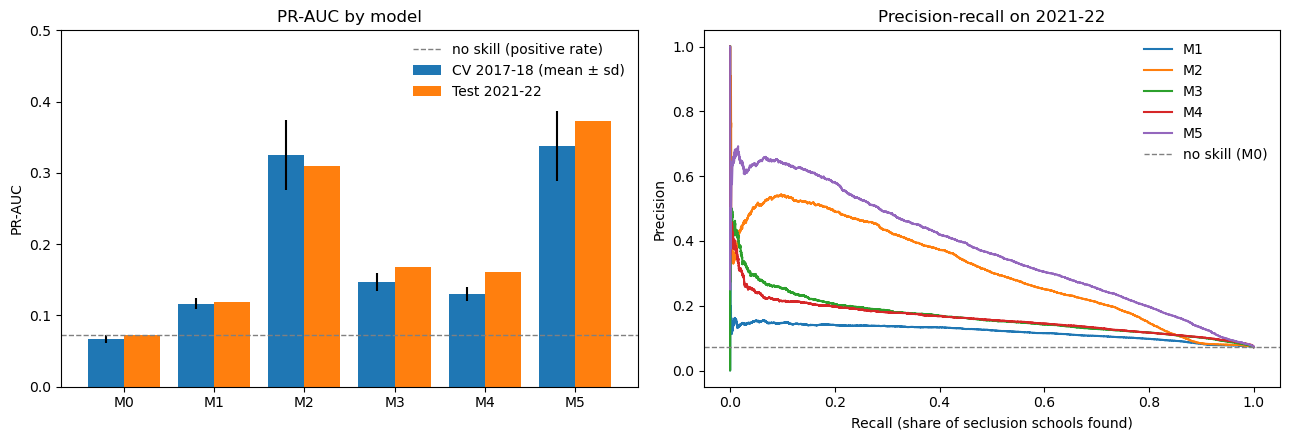

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

wide = summary[summary["metric"] == "pr_auc"].set_index("model")
x = np.arange(len(wide))
axes[0].bar(x - 0.2, wide["cv_mean"], 0.4, yerr=wide["cv_std"], label="CV 2017-18 (mean ± sd)")
axes[0].bar(x + 0.2, wide["test"], 0.4, label="Test 2021-22")
axes[0].axhline(y_test.mean(), color="grey", linestyle="--", linewidth=1, label="no skill (positive rate)")
axes[0].set_xticks(x, wide.index)
axes[0].set_ylabel("PR-AUC")
axes[0].set_ylim(0, 0.5)
axes[0].set_title("PR-AUC by model")
axes[0].legend(frameon=False)

for spec in specs[1:]:  # M0 gives every school the same score, so it has no real curve
    precision, recall, _ = precision_recall_curve(y_test, scores[spec.model_id])
    axes[1].plot(recall, precision, label=spec.model_id, linewidth=1.5)
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", linewidth=1, label="no skill (M0)")
axes[1].set_xlabel("Recall (share of seclusion schools found)")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall on 2021-22")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Calibration:** when a model says 30%, do about 30% of those schools report seclusion? Points
on the diagonal are well calibrated. Bins with few schools are noisy.

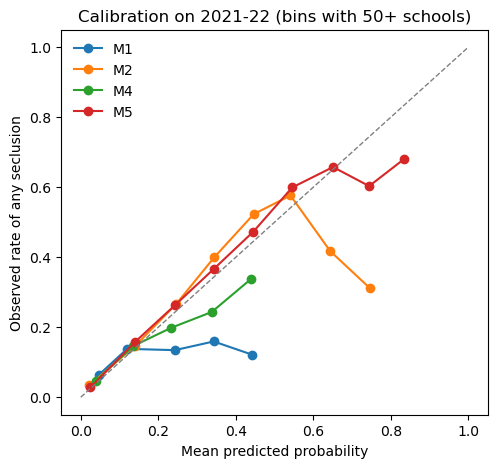

In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for model_id in ("M1", "M2", "M4", "M5"):
    table = tb.calibration_table(y_test, scores[model_id])
    table = table[table["count"] >= 50]
    ax.plot(table["mean_predicted"], table["observed_rate"], marker="o", label=model_id)
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed rate of any seclusion")
ax.set_title("Calibration on 2021-22 (bins with 50+ schools)")
ax.legend(frameon=False)
plt.show()

## 7. What the logistic model (M1) leans on

Coefficients on standardized features, largest first. These are associations, not causes.

In [13]:
m1_builder, m1_model = fitted["M1"]
tb.standardized_coefficients(m1_builder, m1_model).head(15)

,feature,coefficient,abs_coefficient
0,log_enrollment,0.432,0.432
1,gb_high,-0.324,0.324
2,gb_elementary,0.241,0.241
3,pct_idea,0.233,0.233
4,is_charter,-0.220,0.220
5,log_lea_enrollment,-0.214,0.214
6,pct_504,-0.202,0.202
7,pct_el,-0.192,0.192
8,social_p100,0.097,0.097
9,pct_idea_na,0.069,0.069


## Takeaways

- **State carries most of the signal.** Adding state lifts logistic regression (M1 to M2) and
  gradient boosting (M4 to M5) far more than switching model type. Without state, the best
  model is the random forest (M3). State likely reflects state reporting and policy
  differences, not anything about the schools themselves, which matters for how we use it.
- **Gradient boosting + state (M5) is the strongest baseline** on every ranking metric, and its
  probabilities are reasonably calibrated.
- **Watch the 504/EL coding shift.** Compare the two subsets above before trusting the 2021-22
  numbers for those features.

**Open team decisions** are listed in `docs/modeling/README_baseline.md`. Among them: whether
enrollment is an acceptable input, whether to drop PR and HI, whether to include 2020-21, and
whether to predict the same year or forecast next year.

To save the model files and the CSV outputs, run the script instead:
`python scripts/train_baseline.py` (results land in `reports/baseline/` and `models/baseline/`).

## 8. Completed cleaned-data comparison dashboard

Verified November 4, 2026. Six training combinations score the same 2021–22 test set.
The second table uses the same 2,241 new schools for every training combination.
The third table contains within-2021–22 district-grouped CV means, not temporal test scores.

All three years win overall PR-AUC; 2015–16 + 2017–18 win on the common new-school cohort.
See `docs/modeling/cleaned_data_results.md` for reconstructed-input provenance and limitations.
The original sections above remain the 2017–18 baseline walkthrough.

Run `python scripts/summarize_baseline_runs.py` from the repository root to refresh the local CSVs and verify saved M5 scores before re-running this cell.


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

comparison_root = Path.cwd()
if not (comparison_root / "reports").exists():
    comparison_root = comparison_root.parent
comparison_dir = comparison_root / "reports/baseline/comparison"
comparison_columns = ["training_years", "pr_auc", "pr_auc_lift", "recall_at_top10", "roc_auc", "brier"]
for filename, title in [
    ("temporal_test.csv", "M5: temporal test on 2021–22"),
    ("common_new_schools_M5.csv", "M5: identical new-school cohort"),
    ("within_202122_cv.csv", "M5: within-2021–22 district-grouped CV means"),
]:
    comparison = pd.read_csv(comparison_dir / filename)
    if "model" in comparison:
        comparison = comparison[comparison.model.eq("M5")]
    print(title)
    display(comparison[comparison_columns].round(4))


M5: temporal test on 2021–22
M5: identical new-school cohort
M5: within-2021–22 district-grouped CV means


,training_years,pr_auc,pr_auc_lift,recall_at_top10,roc_auc,brier
5,201718,0.3731,5.1739,0.4995,0.8439,0.0542
11,201516,0.3660,5.0746,0.4835,0.8312,0.0557
17,201516 + 201718,0.3946,5.4721,0.5063,0.8439,0.0539
23,202021,0.3918,5.4332,0.5124,0.8429,0.0545
29,201718 + 202021,0.3894,5.3998,0.5201,0.8523,0.0540
35,201516 + 201718 + 202021,0.4090,5.6707,0.5257,0.8510,0.0535


,training_years,pr_auc,pr_auc_lift,recall_at_top10,roc_auc,brier
0,201718,0.2101,3.6784,0.3750,0.6694,0.0501
1,201516,0.2230,3.9039,0.3594,0.7336,0.0499
2,201516 + 201718,0.2469,4.3228,0.4219,0.7065,0.0490
3,202021,0.2063,3.6127,0.3984,0.5865,0.0507
4,201718 + 202021,0.2239,3.9199,0.3672,0.7409,0.0504
5,201516 + 201718 + 202021,0.2248,3.9364,0.4219,0.7243,0.0497


,training_years,pr_auc,pr_auc_lift,recall_at_top10,roc_auc,brier
5,202122,0.3439,4.7781,0.4662,0.8304,0.0559
